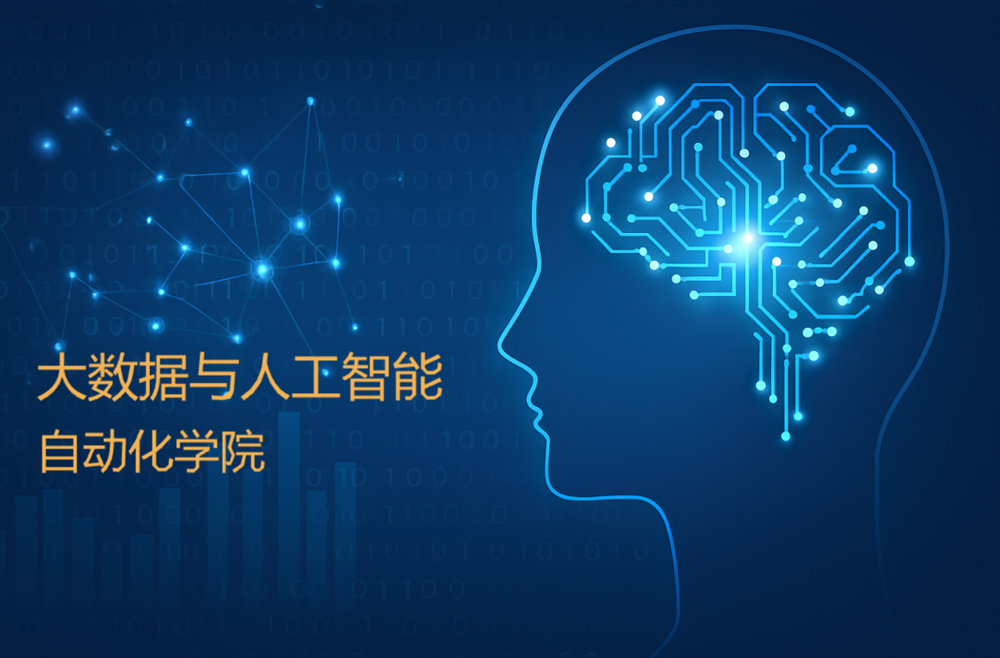

# 第4篇 Transformers 低精度训练篇

# 第4.1课：低精度训练背景与模型下载 (ModelScope)

## 1\. 核心教学内容：为什么要低精度？

### 1.1 大模型训练的显存瓶颈

在之前的课程中，我们使用 4G 显存训练了 0.3B 的 BERT，用 8G 显存训练了 1.4B 的 Bloom。但面对 7B 级别的大模型（如 Llama-2-7B），全量参数或即使是高精度的微调，24G 显存也捉襟见肘。

- **模型权重占用**：FP32（单精度）下，1个参数占4字节。7B模型仅权重就占约 **28GB**，显存直接溢出。
    
- **解决方案**：降低精度。
    
    - **FP16 (Half)**：2字节/参数，显存减半。
        
    - **BF16 (BFloat16)**：2字节/参数，动态范围更大，更适合训练，防止溢出。
        
    - **Int8/FP4**：更低精度（后续课程涉及）。
        



### 1.2 模型下载新姿势：ModelScope

由于 Hugging Face 连接不便，我们使用国内的 **ModelScope (魔搭社区)** 进行模型下载。它被称为“更适合中国宝宝体质的 Hugging Face”。

#### 主网站
- https://www.modelscope.cn/home

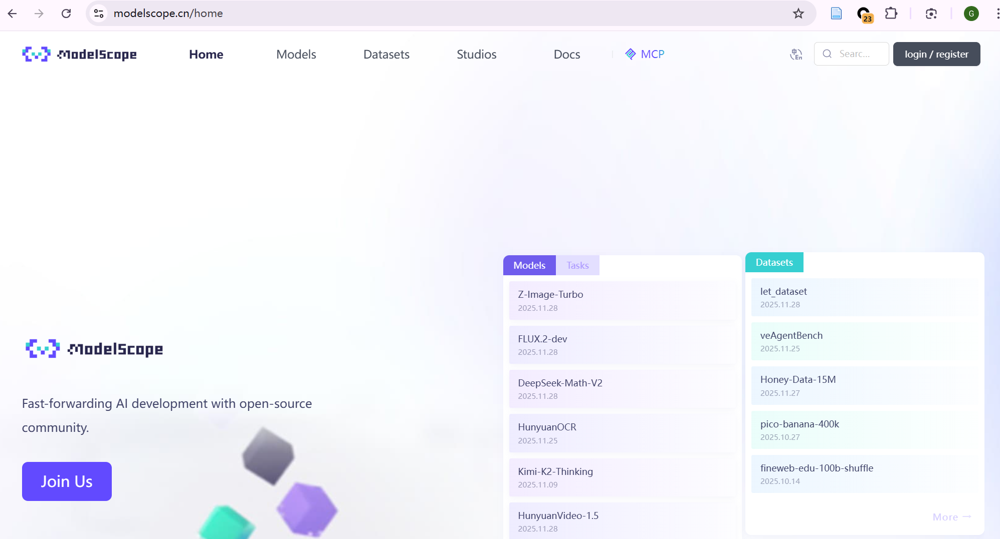


#### 模型页面
- https://www.modelscope.cn/models
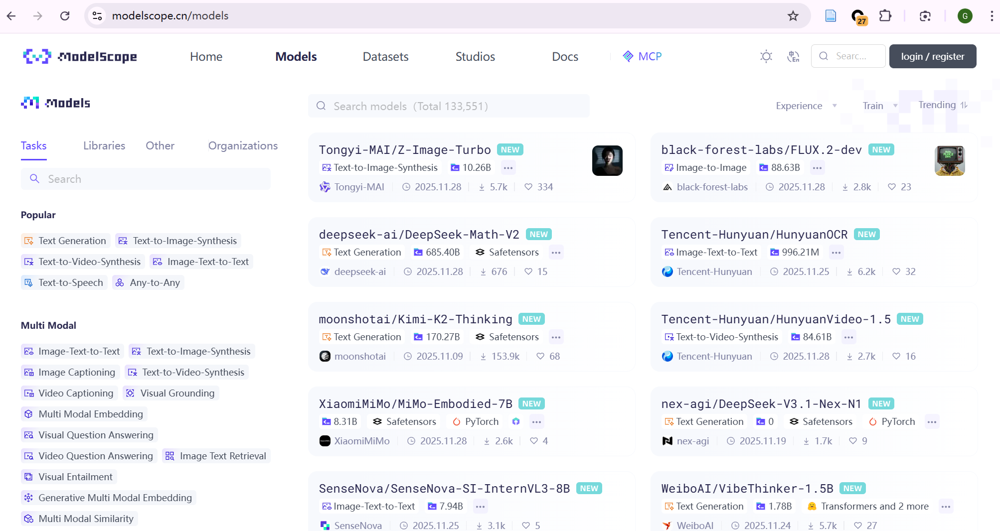


## 2\. 代码实战：下载与加载

### Step 1: 环境准备与模型下载

使用 `modelscope` 库下载 Llama-2 或 ChatGLM3 模型。

Python

In [ ]:
# 这里直接用命令行下载，可以成功
!modelscope download modelscope/Llama-2-7b-ms --cache_dir '/3T/strange007/models' --exclude '*.bin' --revision v1.0.2

In [ ]:
# 这个代码目前好像下载失效
# pip install modelscope
from modelscope.hub.snapshot_download import snapshot_download

# 下载 InternLM 或 Llama2, ChatGLM3 等
# cache_dir: 指定下载到本地的路径
# ignore_file_pattern: 忽略不需要的文件（如 .bin 文件，只下 .safetensors 以节省流量）
model_dir = snapshot_download(
    model_id="Shanghai_AI_Laboratory/internlm-20b", 
    cache_dir="d:/Pretrained_models/",
    ignore_file_pattern=[".*.bin"] 
)

### 下载文件的选择
- https://www.modelscope.cn/models/modelscope/Llama-2-7b-ms/files
- 该模型仓库中同时提供了两种格式的权重文件：

1. **Safetensors 格式**：
    
    - `model-00001-of-00002.safetensors` (9.98GB)
        
    - `model-00002-of-00002.safetensors` (3.50GB)
        
    - **Safetensors** 是一种较新的、更安全且加载速度更快的模型存储格式，逐渐成为 Hugging Face 和 ModelScope 的主流标准。
        
2. **PyTorch Bin 格式**：
    
    - `pytorch_model-00001-of-00003.bin` (9.88GB)
        
    - `pytorch_model-00002-of-00003.bin` (9.89GB)
        
    - `pytorch_model-00003-of-00003.bin` (7.18GB)
        
    - **Bin** 是传统的 PyTorch 权重存储格式（基于 `torch.save`）。
        

**关键点在于：这两组文件包含的是同一套模型参数。** 你只需要下载其中一种格式就可以加载并运行模型。

- 如果不加 `ignore_file_pattern`，脚本会默认下载仓库里的所有文件，意味着你会下载大约 13.5GB 的 safetensors **加上** 大约 27GB 的 bin 文件，总量超过 40GB。
    
- 加上 `ignore_file_pattern=[".*.bin"]` 后，利用正则表达式过滤掉所有以 `.bin` 结尾的文件，只下载 `.safetensors` 文件。这样你只需要下载约 13.5GB 的数据，节省了大量时间和空间。


### Step 2: 加载 Llama-2-7b

ChatGLM 系列不是 Hugging Face 官方库内置的模型结构，因此加载时必须指定 `trust_remote_code=True`，让其执行远程代码库中的逻辑。

Python

In [1]:
import os
# 必须在导入 torch 之前设置， 这样系统只会看到第一张 GPU，Trainer 就不会使用多 GPU。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_path = "/3T/strange007/models/Llama-2-7b-ms"

tokenizer = AutoTokenizer.from_pretrained(
    model_path,
    trust_remote_code=True
)

model = AutoModelForCausalLM.from_pretrained(
    model_path,
    # torch_dtype=torch.float16,      # 避免先以 fp32 进 CPU
    # device_map="cuda:0",            # 直接把权重映射到指定 GPU
    # low_cpu_mem_usage=True,         # edge streaming，显著减小 CPU 峰值
    trust_remote_code=True
)

print(model)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(32000, 4096, padding_idx=0)
    (layers): ModuleList(
      (0-31): 32 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear(in_features=4096, out_features=4096, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (up_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=4096, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((4096,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((4096,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((4096,),


* * *

# 第4.1课：Llama-2 半精度 LoRA 实战与避坑指南

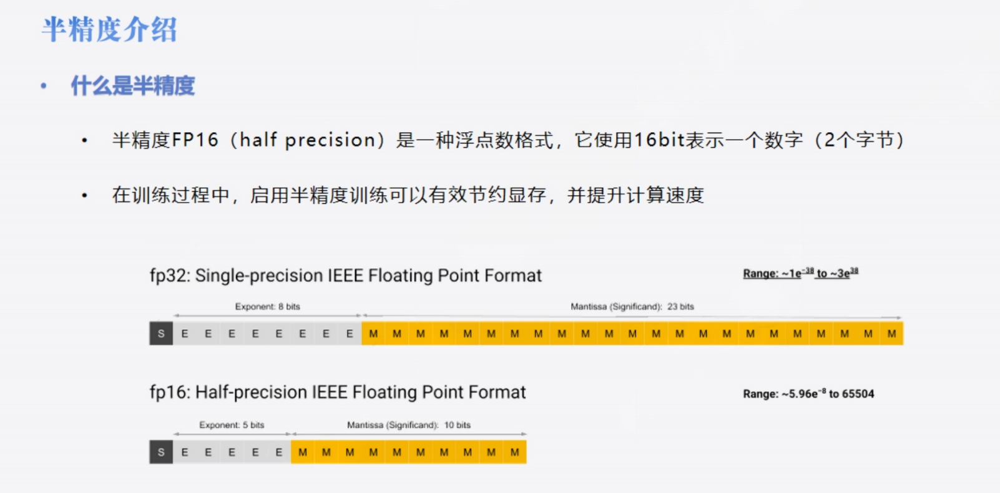

### 半精度介绍 - 什么是半精度**

- **FP16 vs FP32**:
    
    - **FP32 (单精度)**：这是我们通常默认使用的浮点数格式。它占用 **32位（4个字节）**。
        
        - 结构：1位符号位 (S) + 8位指数位 (E) + 23位尾数位 (M)。
            
        - 特点：数值范围很大 ($\approx 10^{-38}$ 到 $10^{38}$)，精度高。
            
    - **FP16 (半精度)**：它只占用 **16位（2个字节）**。
        
        - 结构：1位符号位 (S) + **5位指数位 (E)** + **10位尾数位 (M)**。
            
        - 特点：数值范围大幅缩小 ($\approx 6 \times 10^{-8}$ 到 $65504$)，精度也降低了。
            
- **为什么要用 FP16？**
    
    - **节约显存**：模型参数量减半，可以在同样的显卡上跑更大的模型（Batch Size 可以翻倍）。
        
    - **加速计算**：现代GPU（如NVIDIA Tensor Core）对半精度运算有专门的硬件加速，计算速度显著提升。
        



* * *
### **半精度介绍 - 溢出与舍入问题**

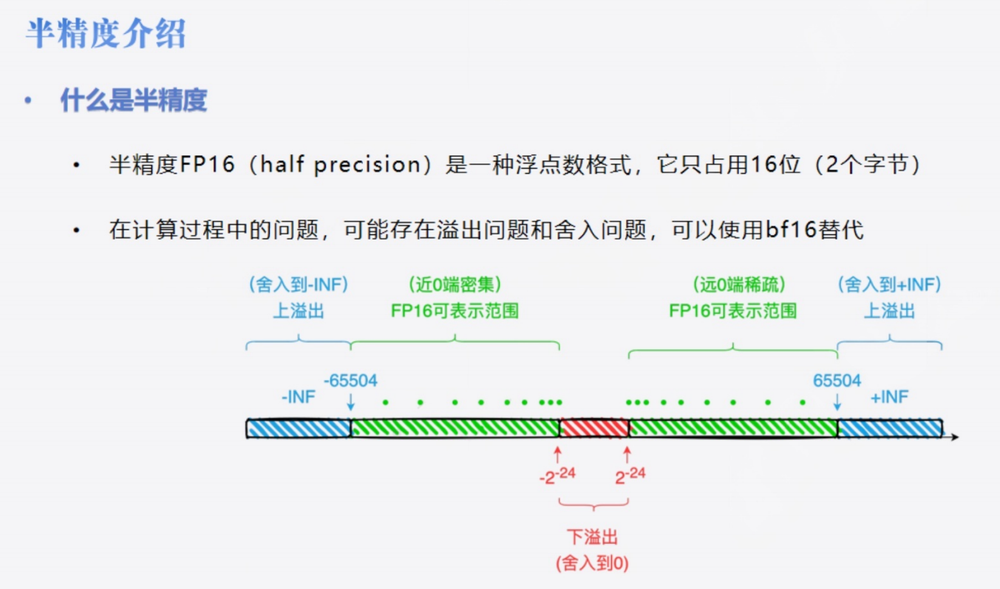


- FP16 因为位数减少而带来的两个核心问题：**溢出 (Overflow)** 和 **下溢出 (Underflow/舍入问题)**。

- **数值范围限制**：
    
    - FP16 能表示的最大正数大约是 **65504**。如果计算结果超过这个数（例如梯度累加时），就会发生**上溢出 (Overflow)**，数值变成无穷大 (INF)，导致训练崩盘。
        
    - FP16 能表示的最小正数大约是 $6 \times 10^{-8}$（甚至更小到 $2^{-24}$ 附近）。如果梯度非常小（例如 $10^{-9}$），就会发生**下溢出**，直接被**舍入为 0**。
        
- **分布特点**：
    
    - 图中的绿色区域是 FP16 的**可表示范围**。
        
    - **近0端密集**：在 0 附近，它能表示的精度较高。
        
    - **远0端稀疏**：随着数值变大，能表示的数字间隔变大，精度变差。
        
    - **解决方法**：可以使用 **bf16 (Brain Floating Point 16)** 替代。bf16 牺牲了尾数位来增加指数位，使得它的数值表示范围和 FP32 一样大，从而避免了上溢出问题，但精度比 FP16 稍低。
        


## 随堂作业
### 5.4.1 为了解决 FP16 的溢出问题，通常推荐使用哪种精度格式（如果硬件支持）？


* * *

### **如何启用半精度训练**

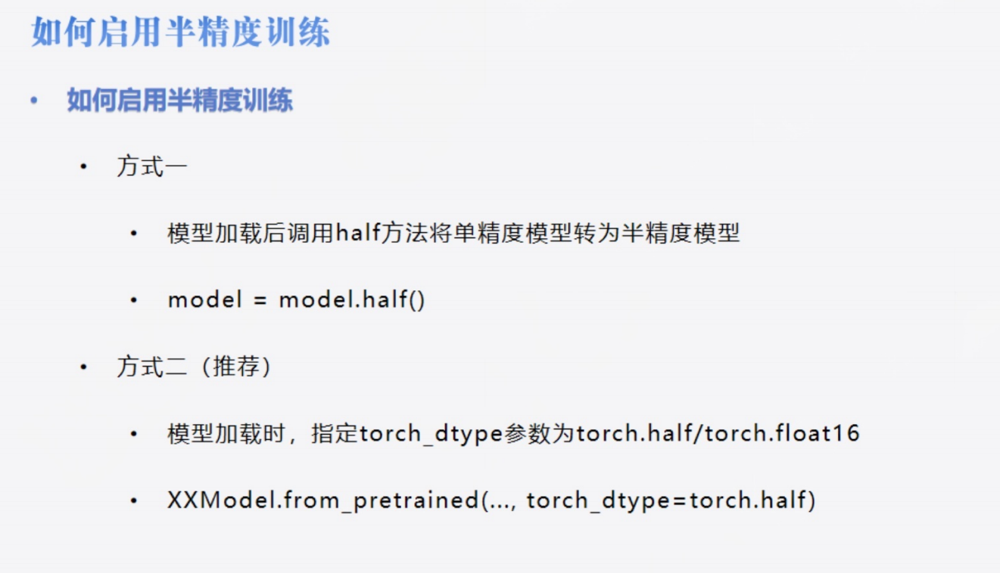

- 在代码层面（PyTorch）如何实操。

- **方式一：模型转换**
    
    - 先加载默认的 FP32 模型，然后手动调用 `.half()` 方法将其转换为半精度。
        
    - 代码：`model = model.half()`
        
    - 缺点：这通常是在模型已经全部加载到内存/显存后才转换，**无法节省加载过程中的内存峰值**。
        
- **方式二（推荐）：加载时指定**
    
    - 直接在 `from_pretrained` 加载模型时，通过 `torch_dtype` 参数指定为 `torch.half` (或 `torch.float16`)。
        
    - 代码：`XXModel.from_pretrained(..., torch_dtype=torch.half)`
        
    - 优点：模型在加载过程中就直接以半精度形式读入，**直接节省一半的内存占用**，这对于在大模型（如 Llama-2-7B）在有限显存上运行至关重要。
        



## 半精度训练实战--Llama2

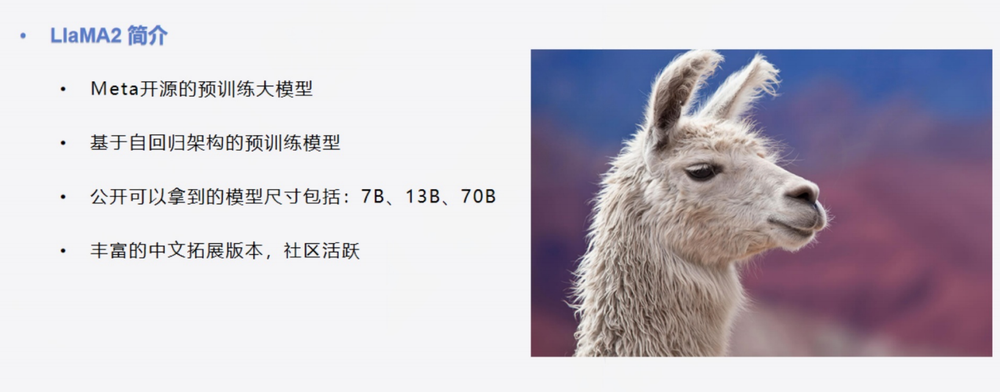

## 1\. 核心教学内容：半精度训练的陷阱

本节课使用 Llama-2-7B 进行半精度（FP16/BF16）LoRA 微调。虽然代码结构与之前类似，但 **7B 模型有许多特定的“坑”** 需要填补。


## 2\. 完整训练流程代码拆解

### Step 1: 数据预处理（含 Bug 修复）

**重点修复**：Llama 的 tokenizer 可能会把 EOS token 和前面的词粘连，或者切分不当。我们需要手动在 `input_ids` 列表末尾添加 `eos_token_id`，并确保 `pad_token_id` 被正确设置。

Python

In [11]:
from datasets import Dataset

ds = Dataset.load_from_disk("./data/alpaca_data_zh/")


In [4]:
import os
# 必须在导入 torch 之前设置， 这样系统只会看到第一张 GPU，Trainer 就不会使用多 GPU。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

# 加载 Tokenizer
model_path = "/3T/strange007/models/Llama-2-7b-ms"
tokenizer = AutoTokenizer.from_pretrained(model_path)

# 坑点1：Llama 默认没有 pad_token，通常使用 unk_token 或 eos_token 代替，或者手动指定 id
tokenizer.pad_token_id = tokenizer.unk_token_id # 或 tokenizer.pad_token_id = 2

# 坑点2：Padding Side 必须为 right，否则多卡或 Batch>1 时不收敛
tokenizer.padding_side = "right" 

def process_func(example):
    MAX_LENGTH = 384 # 适当放大长度，因为中文会被切成多个token
    input_ids, attention_mask, labels = [], [], []
    
    # 构建指令
    instruction = tokenizer("\n".join(["Human: " + example["instruction"], example["input"]]).strip() + "\n\nAssistant: ", add_special_tokens=False)
    
    # 构建回答
    response = tokenizer(example["output"], add_special_tokens=False)
    
    # 坑点3：手动添加 EOS token，确保模型知道何时停止
    # 如果不这样做，推理时模型会一直生成直到最大长度
    input_ids = instruction["input_ids"] + response["input_ids"] + [tokenizer.eos_token_id]
    attention_mask = instruction["attention_mask"] + response["attention_mask"] + [1]
    labels = [-100] * len(instruction["input_ids"]) + response["input_ids"] + [tokenizer.eos_token_id]
    
    # 截断
    if len(input_ids) > MAX_LENGTH:
        input_ids = input_ids[:MAX_LENGTH]
        attention_mask = attention_mask[:MAX_LENGTH]
        labels = labels[:MAX_LENGTH]
        
    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

# ds 是加载好的 Dataset
tokenized_ds = ds.map(process_func, remove_columns=ds.column_names)

Map:   0%|          | 0/26858 [00:00<?, ? examples/s]


### Step 2: 半精度模型加载

使用 `torch_dtype` 开启半精度。

Python

### 避坑点：

1. **分词器问题**：Llama 分词器会将中文字符切碎，且默认没有 `pad_token`。
    
2. **Padding Side**：训练时必须设为 `right`，否则 loss 可能会变成 0 或不收敛。
    
3. **梯度检查点 (Gradient Checkpoint)**：开启后若不处理输入梯度，会报错。
    
4. **EOS Token 丢失**：导致推理时停不下来（这是非常隐蔽的 Bug）。
    


In [5]:
model_path = "/3T/strange007/models/Llama-2-7b-ms"
#
# 显存优化：low_cpu_mem_usage=True
# 精度优化：torch_dtype=torch.bfloat16 (如果显卡支持如3090/4090) 或 torch.half (FP16)
model = AutoModelForCausalLM.from_pretrained(
    model_path, 
    low_cpu_mem_usage=True, 
    torch_dtype=torch.bfloat16, 
    device_map="auto"
)

# 开启梯度检查点以节省显存
model.gradient_checkpointing_enable() 

# 坑点4：开启梯度检查点后，必须执行此方法，否则报错 "element 0 of tensors does not require grad"
#
model.enable_input_require_grads() 

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


In [6]:
print(model)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(32000, 4096, padding_idx=0)
    (layers): ModuleList(
      (0-31): 32 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear(in_features=4096, out_features=4096, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (up_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=4096, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((4096,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((4096,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((4096,),


### Step 3: LoRA 配置与训练

Python

In [7]:
from peft import LoraConfig, TaskType, get_peft_model
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq

# 标准 LoRA 配置
config = LoraConfig(task_type=TaskType.CAUSAL_LM)
model = get_peft_model(model, config)
model.print_trainable_parameters()

# 训练参数
args = TrainingArguments(
    output_dir="./chatbot_llama2",
    per_device_train_batch_size=2, # 配合 padding_side="right" 测试 Batch>1
    gradient_accumulation_steps=8,
    logging_steps=10,
    num_train_epochs=1,
    learning_rate=1e-4, # LoRA 学习率
    fp16=False, # 如果模型已经是 bf16 加载的，这里可以设为 False，或者根据实际情况开启混合精度
    bf16=True   # 推荐开启 bf16
)

trainer = Trainer(
    model=model,
    args=args,
    tokenizer=tokenizer,
    train_dataset=tokenized_ds,
    data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, padding=True),
)

/tmp/ipykernel_2448316/3510778164.py:21: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The model is already on multiple devices. Skipping the move to device specified in `args`.


trainable params: 4,194,304 || all params: 6,742,609,920 || trainable%: 0.0622


In [8]:
trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 0}.
`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step,Training Loss
10,1.267300
20,1.187100
30,1.120300
40,1.028900
50,1.003100
60,0.983300
70,1.035600
80,1.025900
90,1.003300
100,1.004500


KeyboardInterrupt: 


# 第4.2课：8-bit 量化训练实战 (LLM.int8())

## 1\. 核心教学内容：量化原理与 LLM.int8()

### 什么是量化？

量化（Quantization）是一种模型压缩方法，将高精度（如 FP32, FP16）的数值转换为低精度（如 Int8）表示。

- **优势**：
    
    1. **降低显存**：FP16 占2字节，Int8 占1字节，显存减半。
        
    2. **可能加速**：在某些硬件上整数计算更快（但在训练中，由于需要反量化，速度通常反而变慢，主要为了省显存）。
        

### 最基本的 INT8 量化方法：**Absmax（绝对值最大量化）**。

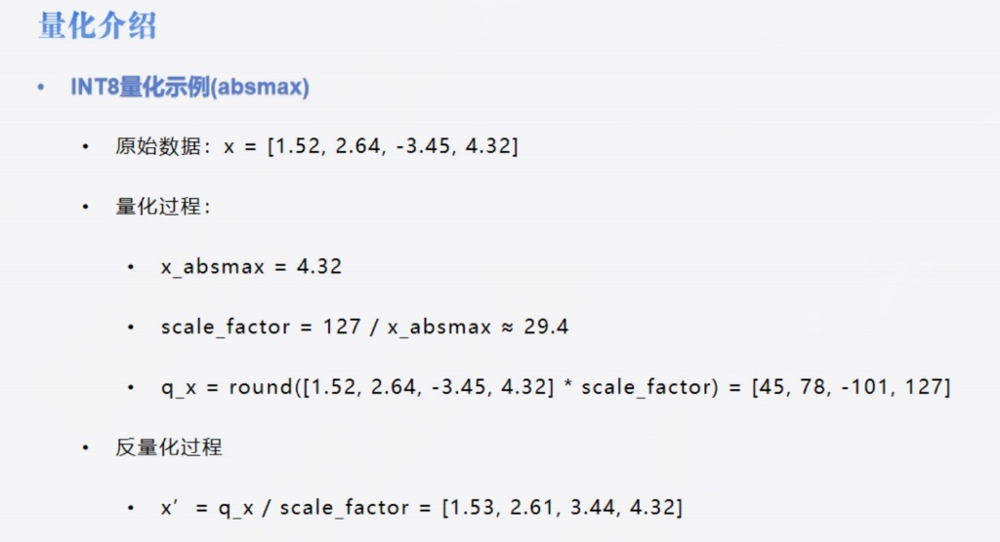

- **目标**：把浮点数（如 4.32）映射到整数范围 [-127, 127]。
    
- **步骤**：
    
    1. **找最大值**：找出数组中绝对值最大的数 `x_absmax` (这里是 4.32)。
        
    2. **计算缩放因子**：`scale_factor = 127 / 4.32 ≈ 29.4`。
        
    3. **量化**：每个数乘以缩放因子并四舍五入。例如 `4.32 * 29.4 = 127`，`-3.45 * 29.4 ≈ -101`。
        
    4. **反量化**：用量化后的整数除以缩放因子，还原回浮点数。
        
- **结果**：你可以看到反量化后的结果 `[1.53, ...]` 与原始数据 `[1.52, ...]` 非常接近。




量化误差的问题。

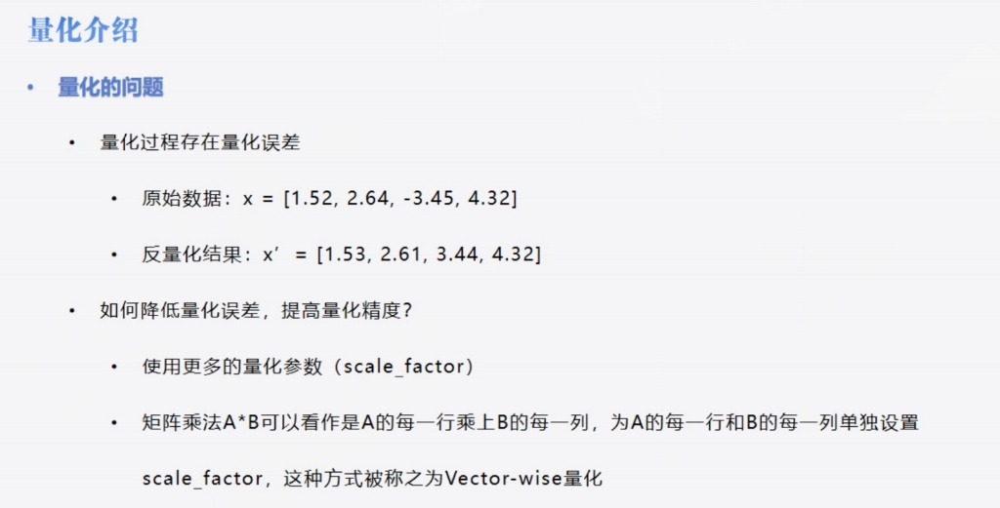


- **问题**：量化是有损的，反量化后的结果 `x'` 不完全等于原始数据 `x`。
    
- **解决方法**：**Vector-wise 量化**。
    
    - 以前可能对整个矩阵用一个 `scale_factor`。
        
    - 现在改为对矩阵的**每一行**或**每一列**单独计算一个 `scale_factor`。这样精度会更高，因为每行数据的分布可能不同。

### 为什么简单的量化不行？(离群值问题)

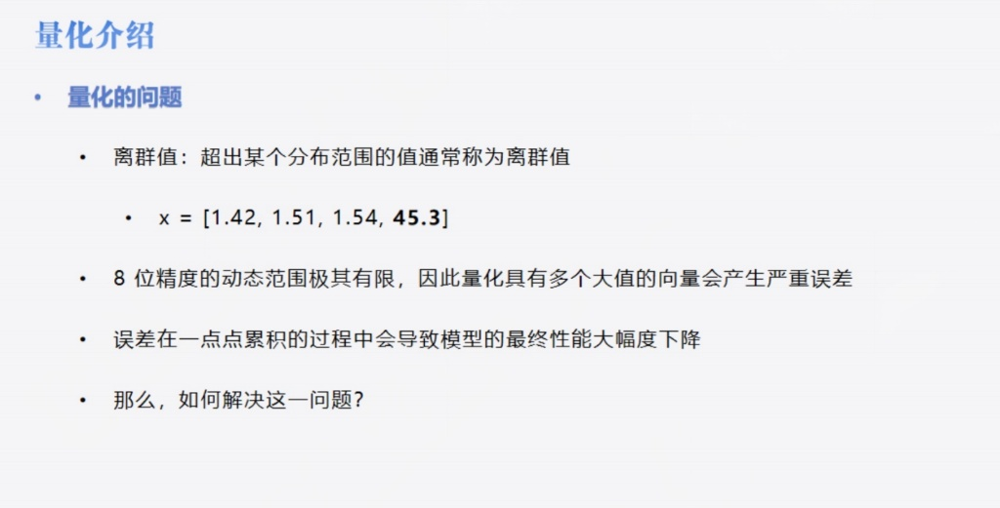


#### 简单量化在遇到**离群值**时的致命缺陷。

- **场景**：数据中突然出现一个特别大的值，例如 `45.3` (其他都在 1.5 左右)。
    
- **后果**：
    
    - `x_absmax` 变成了 45.3。
        
    - `scale_factor` 变得很小 (`127 / 45.3 ≈ 2.8`)。
        
    - **精度崩塌**：原本有差异的小数值（1.42, 1.51），乘以 2.8 后都变成了整数 **4**。它们之间的微小差异消失了！
        
- **结论**：8位量化的动态范围太小，如果有离群值，会严重损害其他正常数值的精度，导致模型性能大幅下降。




### LLM.int8() 的混合精度分解

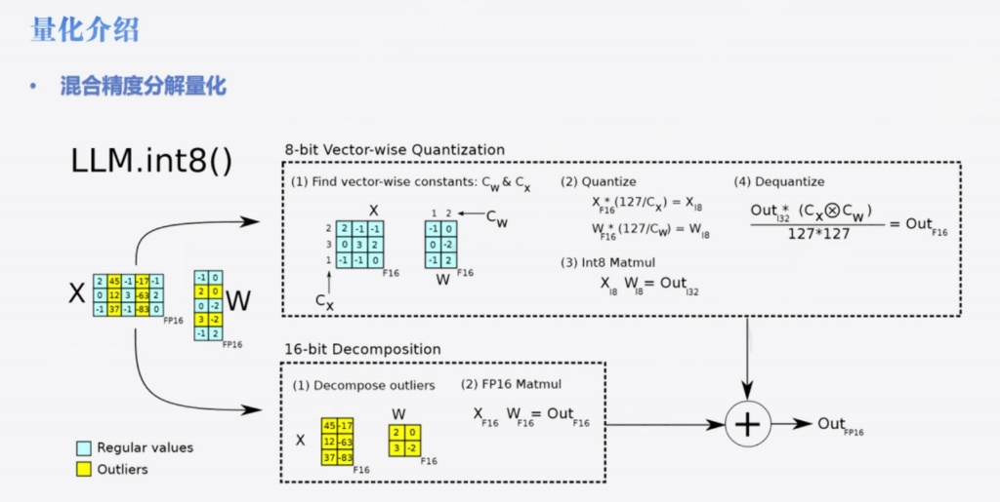

### 解决方案：混合精度分解量化 (LLM.int8())

这两张图展示了 `LLM.int8()` 技术的核心思想，它是如何解决离群值问题的。

- **核心思路**：**分而治之**。
    
- **步骤**：
    
    1. **检测离群值**：在矩阵乘法前，检测输入矩阵 `X` 中哪些列包含离群值（大于某个阈值，例如 6.0）。
        
    2. **分解 (Decomposition)**：
        
        - **黄色部分 (Outliers)**：把包含离群值的列（以及权重矩阵 `W` 中对应的行）单独拆出来。
            
        - **青色部分 (Regular)**：剩下的正常数值。
            
    3. **混合计算**：
        
        - **离群值部分**：保持高精度（**FP16**）进行矩阵乘法，保证精度。
            
        - **正常值部分**：使用 **INT8** 进行量化计算，节省显存和计算量。
            
    4. **合并**：最后将两部分的结果相加，得到最终输出。
        
- **优势**：既享受了 INT8 的省显存优势，又避免了离群值导致的精度崩塌。


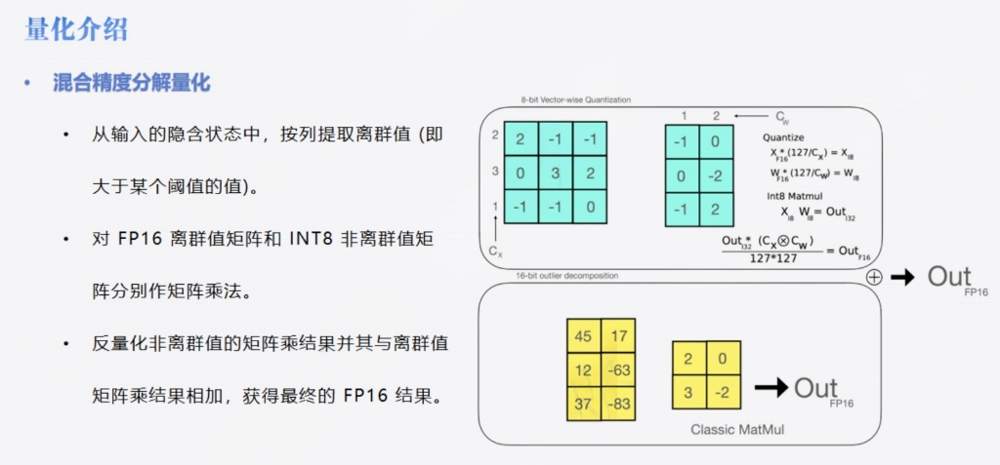


## 随堂作业
### 5.4.2 使用 8-bit 量化 (LLM.int8()) 技术时，它是如何解决“离群值”导致精度崩塌的问题的？



* * *

## 2\. 代码实战：Llama2 & ChatGLM3 的 8-bit 训练

### Step 1: 环境配置

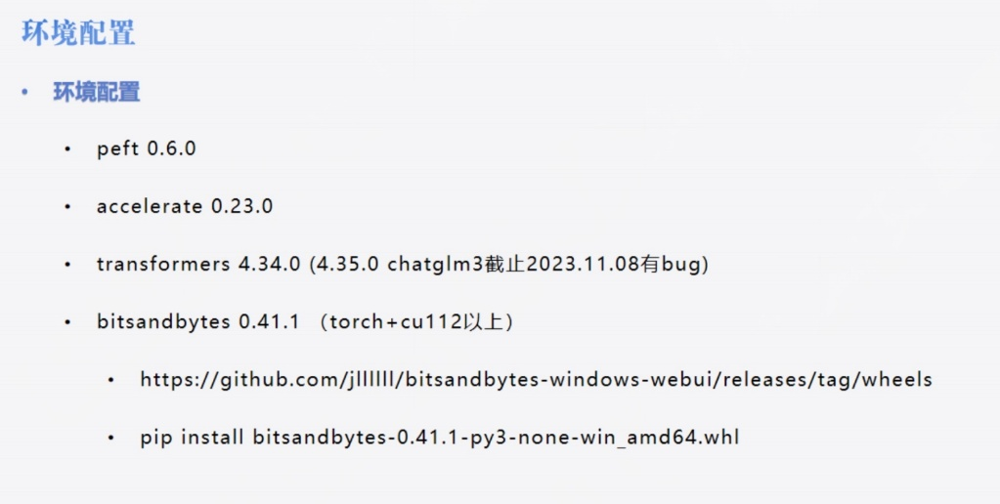

实现上述 `LLM.int8()` 所需的软件环境（主要是针对 ChatGLM3-6B 的配置建议）：

- **核心库**：`bitsandbytes` (提供底层的 8-bit 优化算子)。
    
- **依赖**：`peft`, `accelerate`, `transformers`。
    
- **注意**：Windows 用户通常需要手动下载预编译的 `bitsandbytes` whl 包。


### Step 2: 模型加载 (核心差异点)

我们在加载模型时，只需要添加 `load_in_8bit=True`。

**Llama2-7B 8-bit 加载:**

Python

In [1]:
import os
# 必须在导入 torch 之前设置， 这样系统只会看到第一张 GPU，Trainer 就不会使用多 GPU。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, DataCollatorForSeq2Seq, TrainingArguments, Trainer

model_path = "/3T/strange007/models/Llama-2-7b-ms"
model = AutoModelForCausalLM.from_pretrained(
    model_path, 
    low_cpu_mem_usage=True, 
    torch_dtype=torch.bfloat16, 
    device_map="auto", 
    load_in_8bit=True  # 核心参数：开启8bit量化加载
)

# 打印参数查看数据类型
#
for name, param in model.named_parameters():
    print(name, param.shape, param.dtype)
# 你会发现大部分 Linear 层变成了 int8 类型

`torch_dtype` is deprecated! Use `dtype` instead!
The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


model.embed_tokens.weight torch.Size([32000, 4096]) torch.bfloat16
model.layers.0.self_attn.q_proj.weight torch.Size([4096, 4096]) torch.int8
model.layers.0.self_attn.k_proj.weight torch.Size([4096, 4096]) torch.int8
model.layers.0.self_attn.v_proj.weight torch.Size([4096, 4096]) torch.int8
model.layers.0.self_attn.o_proj.weight torch.Size([4096, 4096]) torch.int8
model.layers.0.mlp.gate_proj.weight torch.Size([11008, 4096]) torch.int8
model.layers.0.mlp.up_proj.weight torch.Size([11008, 4096]) torch.int8
model.layers.0.mlp.down_proj.weight torch.Size([4096, 11008]) torch.int8
model.layers.0.input_layernorm.weight torch.Size([4096]) torch.bfloat16
model.layers.0.post_attention_layernorm.weight torch.Size([4096]) torch.bfloat16
model.layers.1.self_attn.q_proj.weight torch.Size([4096, 4096]) torch.int8
model.layers.1.self_attn.k_proj.weight torch.Size([4096, 4096]) torch.int8
model.layers.1.self_attn.v_proj.weight torch.Size([4096, 4096]) torch.int8
model.layers.1.self_attn.o_proj.weight


**ChatGLM3-6B 8-bit 加载:**

Python

In [ ]:
# model_path = "/3T/strange007/models/chatglm3-6b-base"

# model = AutoModelForCausalLM.from_pretrained(
#     model_path, 
#     trust_remote_code=True, 
#     low_cpu_mem_usage=True, 
#     torch_dtype=torch.bfloat16, 
#     device_map="auto", 
#     load_in_8bit=True # 同样只需这一行
# )


### Step 3: 数据预处理

（此处沿用前面的逻辑，Llama2 注意 padding_side="right" 和 EOS token，ChatGLM3 注意 build_chat_input）

Python

In [2]:
#
tokenizer = AutoTokenizer.from_pretrained(model_path)
tokenizer.padding_side = "right"
tokenizer.pad_token_id = 2 # 或 tokenizer.unk_token_id

# 处理函数略（同前几课，确保 input_ids 包含 eos_token_id）

In [3]:
from datasets import Dataset

ds = Dataset.load_from_disk("./data/alpaca_data_zh/")


In [4]:
import os
# 必须在导入 torch 之前设置， 这样系统只会看到第一张 GPU，Trainer 就不会使用多 GPU。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

# 加载 Tokenizer
model_path = "/3T/strange007/models/Llama-2-7b-ms"
tokenizer = AutoTokenizer.from_pretrained(model_path)

# 坑点1：Llama 默认没有 pad_token，通常使用 unk_token 或 eos_token 代替，或者手动指定 id
tokenizer.pad_token_id = tokenizer.unk_token_id # 或 tokenizer.pad_token_id = 2

# 坑点2：Padding Side 必须为 right，否则多卡或 Batch>1 时不收敛
tokenizer.padding_side = "right" 

def process_func(example):
    MAX_LENGTH = 384 # 适当放大长度，因为中文会被切成多个token
    input_ids, attention_mask, labels = [], [], []
    
    # 构建指令
    instruction = tokenizer("\n".join(["Human: " + example["instruction"], example["input"]]).strip() + "\n\nAssistant: ", add_special_tokens=False)
    
    # 构建回答
    response = tokenizer(example["output"], add_special_tokens=False)
    
    # 坑点3：手动添加 EOS token，确保模型知道何时停止
    # 如果不这样做，推理时模型会一直生成直到最大长度
    input_ids = instruction["input_ids"] + response["input_ids"] + [tokenizer.eos_token_id]
    attention_mask = instruction["attention_mask"] + response["attention_mask"] + [1]
    labels = [-100] * len(instruction["input_ids"]) + response["input_ids"] + [tokenizer.eos_token_id]
    
    # 截断
    if len(input_ids) > MAX_LENGTH:
        input_ids = input_ids[:MAX_LENGTH]
        attention_mask = attention_mask[:MAX_LENGTH]
        labels = labels[:MAX_LENGTH]
        
    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

# ds 是加载好的 Dataset
tokenized_ds = ds.map(process_func, remove_columns=ds.column_names)


### Step 4: LoRA 配置与准备

在使用 8-bit 模型进行 LoRA 训练时，需要额外调用 `enable_input_require_grads()`。

Python

In [5]:
#
from peft import LoraConfig, TaskType, get_peft_model

config = LoraConfig(task_type=TaskType.CAUSAL_LM)
model = get_peft_model(model, config)

# 开启梯度检查点时，必须执行该方法，否则报错
#
model.enable_input_require_grads() 

model.print_trainable_parameters()

trainable params: 4,194,304 || all params: 6,742,609,920 || trainable%: 0.0622



### Step 5: 训练参数与显存观察

8-bit 训练虽然速度变慢，但显存显著降低。7B 模型全量微调需 24G+，8-bit LoRA 仅需 10G 左右。

Python

In [6]:
#
args = TrainingArguments(
    output_dir="./chatbot",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=32, # 显存够可以调大
    logging_steps=10,
    num_train_epochs=1,
    gradient_checkpointing=True # 开启梯度检查点进一步省显存
)

trainer = Trainer(
    model=model,
    args=args,
    tokenizer=tokenizer,
    train_dataset=tokenized_ds.select(range(6000)), # 演示用，取部分数据
    data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, padding=True),
)


/tmp/ipykernel_2557241/4120099464.py:11: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [ ]:

trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 0}.
`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/3T/strange007/miniconda3/envs/teach/lib/python3.12/site-packages/bitsandbytes/autograd/_functions.py:181: UserWarning: MatMul8bitLt: inputs will be cast from torch.bfloat16 to float16 during quantization
  warnings.warn(f"MatMul8bitLt: inputs will be cast from {A.dtype} to float16 during quantization")


Step,Training Loss
10,1.245800
20,1.223600
30,1.167200
40,1.155900



* * *

# 第4.3课：4-bit QLoRA 训练实战

## 1\. 核心教学内容：QLoRA 的三大创新

4-bit 量化比 8-bit 更激进，如果直接线性量化会造成巨大精度损失。**QLoRA (Quantized LoRA)** 引入了三项技术来解决这个问题：

1. **NF4 (Normal Float 4) 数据类型**：
    
    - 预训练模型的权重通常符合正态分布。
        
    - NF4 是一种基于分位数（Quantile）的量化方法，专门针对正态分布设计，比标准的 Int4 精度更高。
        
2. **双重量化 (Double Quantization)**：
    
    - 量化本身需要存储“量化常数”（Scale Factor）。
        
    - QLoRA 对这些量化常数再进行一次 8-bit 量化，进一步节省每参数约 0.37 bit 的显存。
        
3. **分页优化器 (Paged Optimizers)**：
    
    - 当显存不足以存储优化器状态时（如梯度更新瞬间），自动将优化器状态转移到 CPU 内存中，防止 OOM（显存溢出）。
        


### 量化基础回顾

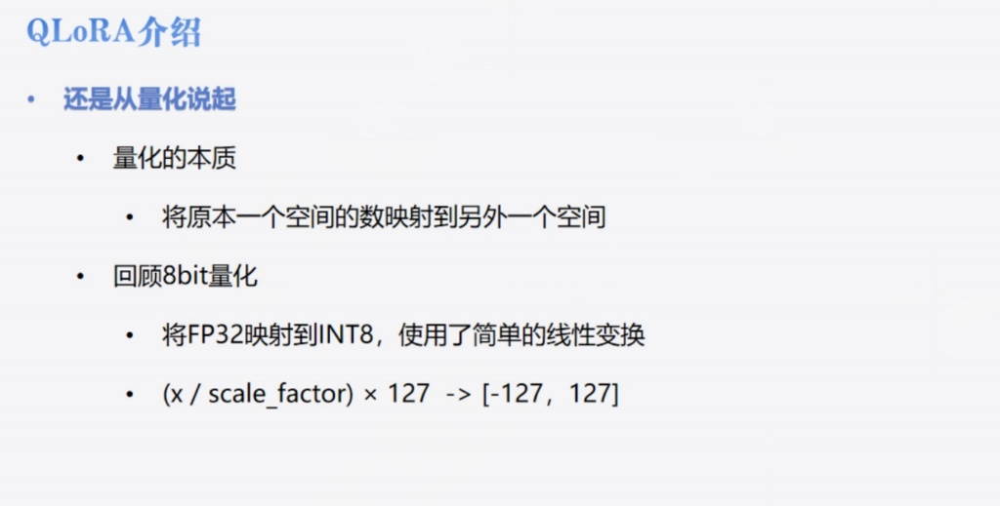

量化的本质：将高精度数值映射到低精度空间。

- **Int8 量化**：使用线性变换 `(x / scale_factor) * 127` 将 FP32 映射到 [-127, 127]。

### 线性量化的局限性 (4-bit)

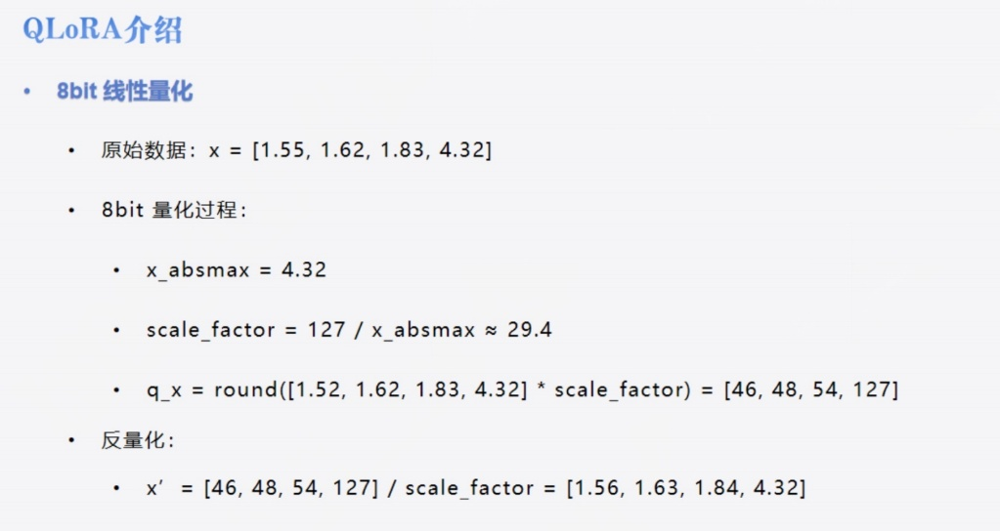


这几张图展示了当我们将量化进一步压缩到 **4-bit** 时会发生什么。

- **Int8 线性量化**（图1）：原始数据 `[1.55, 1.62, 1.83, 4.32]`，通过 Absmax 量化后，还能保留一定的差异（46, 48, 54, 127）。
    

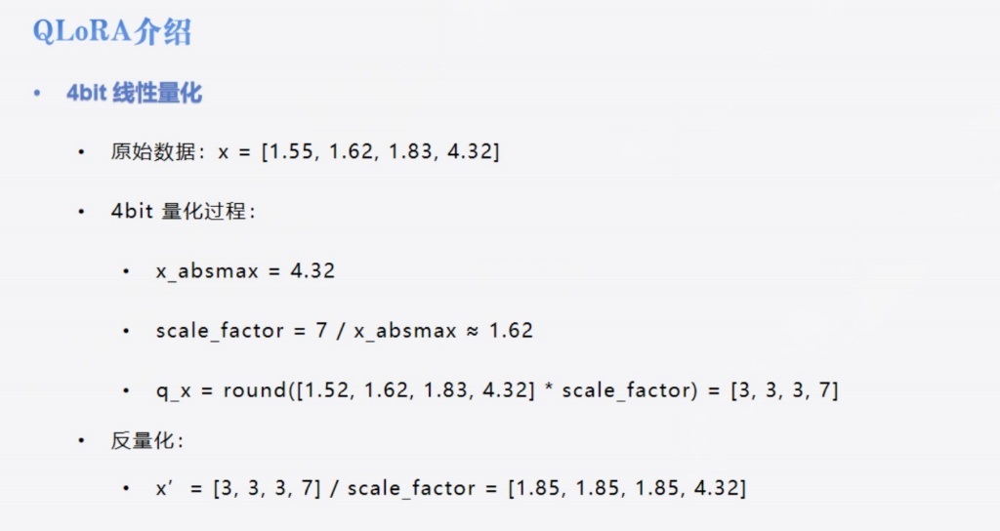

- **Int4 线性量化**（图2）：

    - 4-bit 只有 16 个刻度（[-8, 7] 或 [0, 15]）。
        
    - 同样的原始数据，量化后变成了 `[3, 3, 3, 7]`。
        
    - **问题**：原本有差异的 `1.55, 1.62, 1.83` 全部变成了 **3**。大量信息丢失，量化误差巨大。
        
    - **原因**（图3）：线性量化是在目标域（[-1, 1]）做**均匀切分**。但真实权重的分布并不均匀，如果分布不匹配，会导致大量数值落在同一个区间内。

    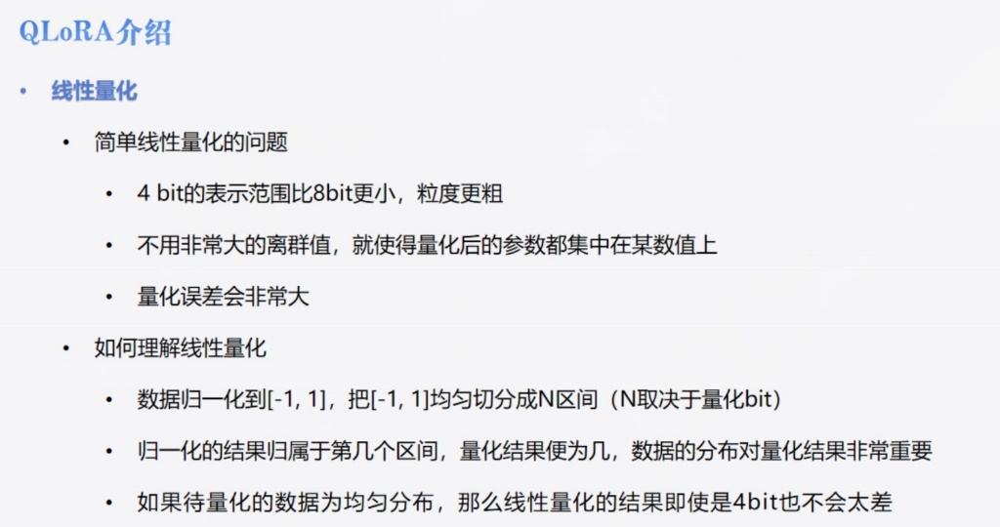

### 模型权重的真实分布 (正态分布)

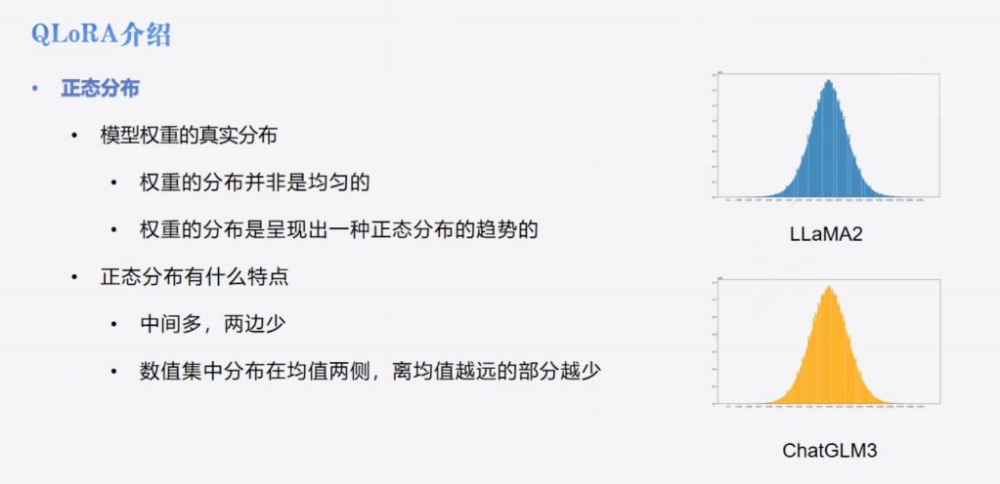

这张图展示了 LLaMA2 和 ChatGLM3 模型的真实权重分布直方图。

- **特点**：呈现明显的 **钟形曲线（正态分布）**。
    
- **含义**：大部分数值集中在 0 附近（中间多），两端数值很少（两边少）。
    
- **启示**：既然权重不是均匀分布的，那么**均匀量化（线性量化）就是低效的**。我们应该在数值密集的地方（0附近）多切几刀，在稀疏的地方（两端）少切几刀。



### 分位数与 NF4 (Normal Float 4)

为了解决上述问题，QLoRA 引入了基于分位数的量化方法，特别是 **NF4**。

- **分位数量化**：
    
    - 不再均匀切分数值，而是**按数据点的数量均分**（例如中位数、四分位数）。
        
    - 保证每个量化区间内落入的数值个数大致相等。


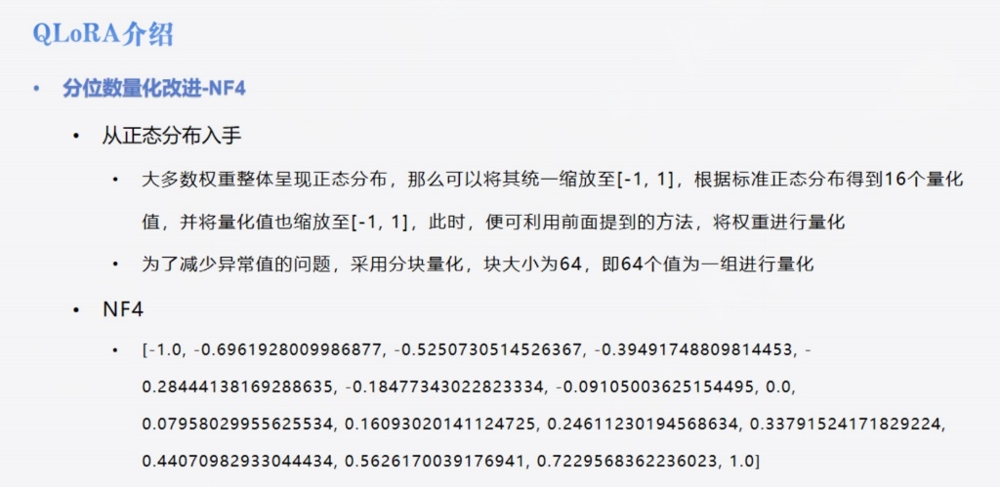

- **NF4 (Normal Float 4)**（上图）：
    
    - **原理**：既然我们知道权重服从正态分布，那我们就根据标准正态分布的累积分布函数（CDF），计算出将正态分布切分成等概率的 16 个区间的**分位点**。
        
    - **NF4 数据类型**：这 16 个特定的分位点数值（如图中列出的 `-1.0, -0.69, ..., 0.72, 1.0`）就构成了 NF4 数据类型。
        
    - **优势**：这是理论上对正态分布数据进行 4-bit 量化的**最优解**，能最大程度保留精度。

### NF4 量化完整示例


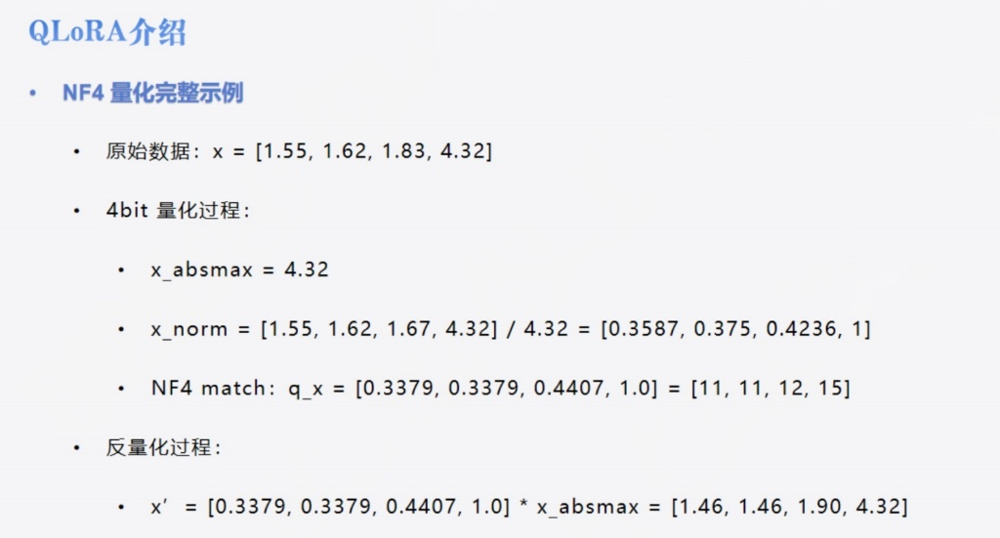

这张图用一个具体的例子展示了 **NF4 (Normal Float 4)** 是如何工作的。

- **原始数据**：`[1.55, 1.62, 1.83, 4.32]`。
    
- **步骤**：
    
    1. **归一化 (Normalize)**：找出最大绝对值 `x_absmax=4.32`，将所有数据除以它，缩放到 `[-1, 1]` 区间。
        
    2. **NF4 匹配 (Match)**：这是核心。不像线性量化那样直接乘缩放因子，而是去查 **NF4 分位点表**（见上一组图的 NF4 数值列表）。
        
        - 比如归一化后的 `0.3587`，在 NF4 表中最接近的值是 `0.3379`（对应索引 11）。
            
        - `0.4236` 最接近 `0.4407`（对应索引 12）。
            
    3. **反量化**：用匹配到的 NF4 数值乘以 `x_absmax` 还原。
        
- **结果**：反量化结果 `[1.46, 1.46, 1.90, 4.32]`。相比于线性量化（之前例子中都变成了3），NF4 更好地保留了数值间的差异。


### 双重量化 (Double Quantization)

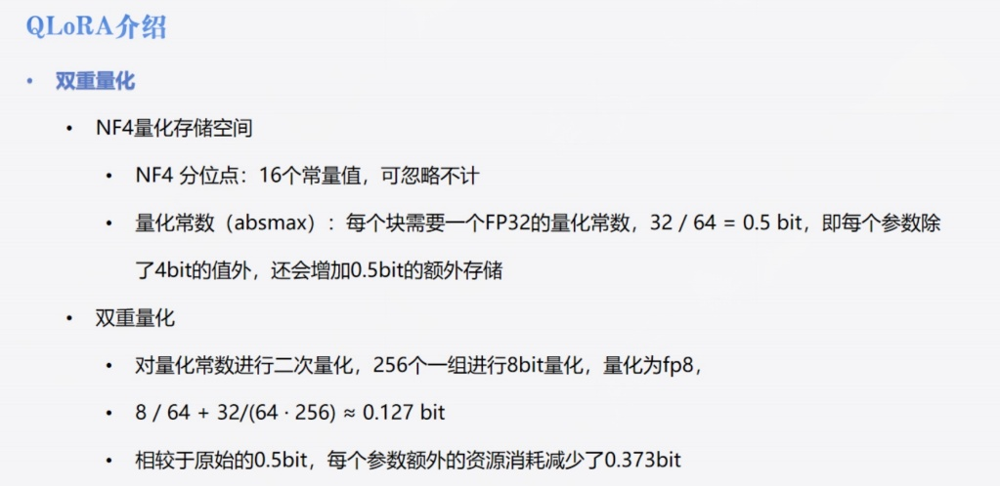

这张图解释了 QLoRA 如何进一步“压榨”显存。

- **痛点**：虽然权重本身被量化成了 4-bit，但为了反量化，我们需要存储量化常数（`absmax`）。
    
    - 通常每 64 个参数（Block Size=64）共享一个 FP32 的量化常数。
        
    - 这带来了额外的开销：`32 bit / 64 = 0.5 bit/参数`。
        
- **解决方案**：对这些 **量化常数** 再进行一次量化（即“双重”）。
    
    - 把 FP32 的量化常数每 256 个一组，量化成 FP8（8-bit）。
        
    - **收益**：额外开销从 `0.5 bit` 降到了 `0.127 bit`。这看似微小，但在百亿参数的模型上，节省的显存非常可观。

### 分页优化器 (Paged Optimizers)

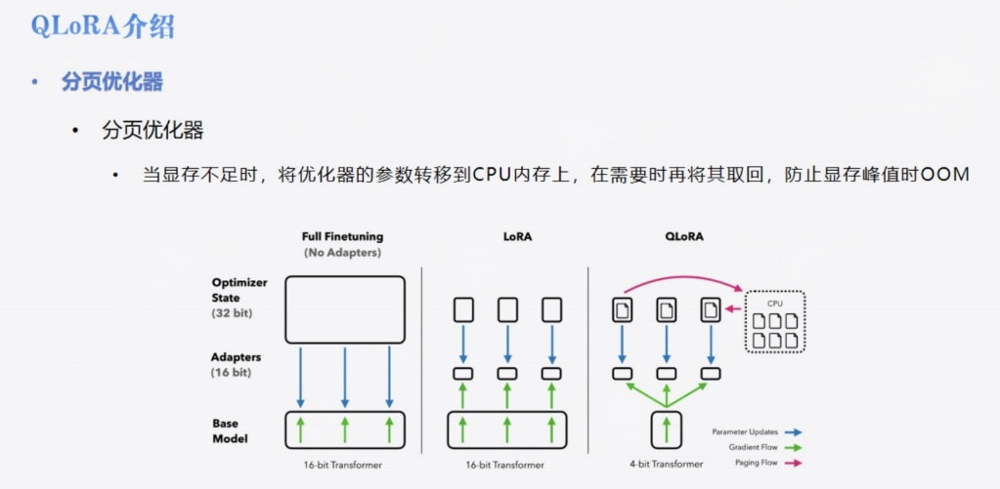

这张图解决了显存溢出（OOM）的另一个大头：**优化器状态（Optimizer States）**。

- **问题**：在训练（反向传播）时，梯度更新会导致显存占用瞬间飙升，容易 OOM。
    
- **原理**：借鉴了操作系统的 **虚拟内存（Paging）** 机制。
    
    - 它可以将优化器的状态（如 Adam 的动量信息）自动在 **GPU 显存** 和 **CPU 内存** 之间进行换页传输。
        
- **效果**：
    
    - 当 GPU 显存紧张时，自动把暂时不用的优化器状态“踢”到 CPU 内存里。
        
    - 需要更新参数时，再从 CPU 内存“拉”回来。
        
    - 这使得我们可以在单张显卡上微调比以前大得多的模型。

## 随堂作业
### 5.4.3 QLoRA 引入的“双重量化 (Double Quantization)”技术的主要作用是？


## 2\. 代码实战：在单卡上训练大模型

### Step 1: 环境与配置

需要 `bitsandbytes >= 0.39.0` 和最新版的 `transformers`。

### Step 2: 模型加载 (QLoRA 核心配置)

通过 `transformers` 加载模型时，需要详细配置 `BitsAndBytesConfig`（或者直接传参数）。

**Llama2-13B 4-bit 加载 (单卡 24G 显存通常跑不动 13B 全量，但 QLoRA 可以):**

Python

In [ ]:
#
import torch
from transformers import AutoModelForCausalLM

model_path = "/3T/strange007/models/Llama-2-13b-ms"

model = AutoModelForCausalLM.from_pretrained(
    model_path, 
    low_cpu_mem_usage=True, 
    torch_dtype=torch.bfloat16, 
    device_map="auto", 
    
    # --- QLoRA 核心参数 ---
    load_in_4bit=True,                  # 开启 4-bit 量化
    bnb_4bit_compute_dtype=torch.bfloat16, # 计算时使用的精度（反量化后）
    bnb_4bit_quant_type="nf4",          # 使用 NF4 数据类型
    bnb_4bit_use_double_quant=True      # 开启双重量化
)


**ChatGLM3-6B 4-bit 加载:**

Python

In [ ]:
# #
# # 显存占用极低，约 4G-6G 即可训练
# model = AutoModelForCausalLM.from_pretrained(
#     "d:/Pretrained_models/ZhipuAI/chatglm3-6b-base/", 
#     trust_remote_code=True, 
#     low_cpu_mem_usage=True, 
#     torch_dtype=torch.bfloat16, 
#     device_map="auto", 
#     load_in_4bit=True, 
#     bnb_4bit_compute_dtype=torch.bfloat16,
#     bnb_4bit_quant_type="nf4", 
#     bnb_4bit_use_double_quant=True
# )


**InternLM-20B 4-bit 加载:**

演示如何在单卡上跑起来 20B 规模的模型（通常全精度需要 40G+ 显存，4-bit QLoRA 仅需 14G 左右）。代码配置同上。

### Step 3: 分页优化器 (Paged Optimizer)

在 `TrainingArguments` 中指定优化器类型，这是防止显存峰值溢出的关键。

Python

In [ ]:
#
args = TrainingArguments(
    output_dir="./chatbot",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=32,
    logging_steps=10,
    num_train_epochs=1,
    gradient_checkpointing=True,
    
    # 核心参数：使用分页优化器
    # 如果显存不够，优化器状态会自动换出到 CPU RAM
    optim="paged_adamw_32bit" 
)


### Step 4: 完整训练流程

训练流程与标准 LoRA 一致，但因为加载了 4-bit，模型实际上是冻结的，LoRA 适配器是 FP16/BF16。

Python

In [ ]:
# LoRA 配置
config = LoraConfig(task_type=TaskType.CAUSAL_LM)
model = get_peft_model(model, config)
model.enable_input_require_grads() 

# 训练器
trainer = Trainer(
    model=model,
    args=args,
    tokenizer=tokenizer,
    train_dataset=tokenized_ds.select(range(6000)),
    data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, padding=True),
)

trainer.train()